# EDA Theory Project
## Air Quality Analysis and Next-Day PM2.5 Forecasting — Dongsi Station, Beijing
Dataset: *Beijing Multi-Site Air-Quality Data Set* (Kaggle), hourly data from 1 March 2013 to 28 February 2017.

### 1. Importing libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
%config InlineBackend.figure_format = 'retina'

### 2. Loading the dataset

In [2]:
df = pd.read_csv("data/PRSA_Data_Dongsi_20130301-20170228.csv")
print("Rows:", df.shape[0], " Columns:", df.shape[1])
df.head()

Rows: 35064  Columns: 18


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,9.0,9.0,3.0,17.0,300.0,89.0,-0.5,1024.5,-21.4,0.0,NNW,5.7,Dongsi
1,2,2013,3,1,1,4.0,4.0,3.0,16.0,300.0,88.0,-0.7,1025.1,-22.1,0.0,NW,3.9,Dongsi
2,3,2013,3,1,2,7.0,7.0,NaN,17.0,300.0,60.0,-1.2,1025.3,-24.6,0.0,NNW,5.3,Dongsi
3,4,2013,3,1,3,3.0,3.0,5.0,18.0,NaN,NaN,-1.4,1026.2,-25.5,0.0,N,4.9,Dongsi
4,5,2013,3,1,4,3.0,3.0,7.0,NaN,200.0,84.0,-1.9,1027.1,-24.5,0.0,NNW,3.2,Dongsi


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       35064 non-null  int64  
 1   year     35064 non-null  int64  
 2   month    35064 non-null  int64  
 3   day      35064 non-null  int64  
 4   hour     35064 non-null  int64  
 5   PM2.5    34314 non-null  float64
 6   PM10     34511 non-null  float64
 7   SO2      34401 non-null  float64
 8   NO2      33463 non-null  float64
 9   CO       31867 non-null  float64
 10  O3       34400 non-null  float64
 11  TEMP     35044 non-null  float64
 12  PRES     35044 non-null  float64
 13  DEWP     35044 non-null  float64
 14  RAIN     35044 non-null  float64
 15  wd       34986 non-null  str    
 16  WSPM     35050 non-null  float64
 17  station  35064 non-null  str    
dtypes: float64(11), int64(5), str(2)
memory usage: 4.8 MB


### 3. Preparing the data

In [4]:
print("Stations in file:", df["station"].unique().tolist())

# build one datetime column from year, month, day and hour
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.set_index("datetime")
df = df.drop(columns=["No", "year", "month", "day", "hour", "station"])

# check duplicates and whether every hour is present
full_range = pd.date_range(df.index.min(), df.index.max(), freq="h")
print("Duplicate rows       :", df.duplicated().sum())
print("Duplicate timestamps :", df.index.duplicated().sum())
print("Expected hours       :", len(full_range), " Rows present:", len(df))

Stations in file: ['Dongsi']
Duplicate rows       : 0
Duplicate timestamps : 0
Expected hours       : 35064  Rows present: 35064


### 4. Missing values

In [5]:
def longest_gap(s):
    # longest run of consecutive missing hours in a column
    runs = s.isna().astype(int).groupby(s.notna().cumsum()).sum()
    return runs.max()

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "longest_gap_hours": [longest_gap(df[c]) for c in df.columns]
})
missing.sort_values("missing_pct", ascending=False)

,missing_count,missing_pct,longest_gap_hours
CO,3197,9.12,1517
NO2,1601,4.57,900
PM2.5,750,2.14,58
SO2,663,1.89,57
O3,664,1.89,57
PM10,553,1.58,57
wd,78,0.22,5
TEMP,20,0.06,6
PRES,20,0.06,6
DEWP,20,0.06,6


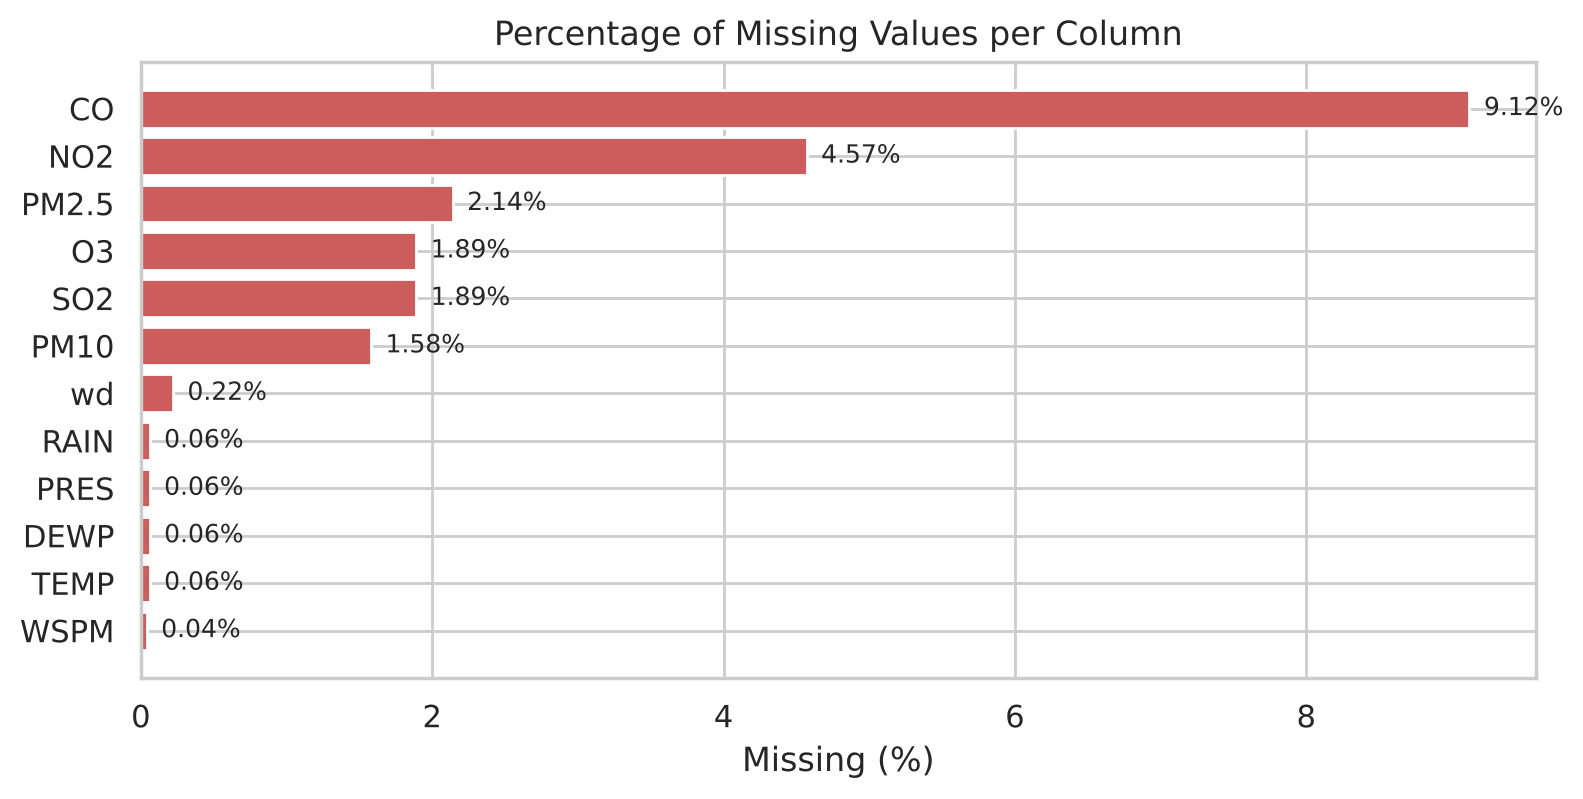

In [6]:
miss = missing[missing["missing_count"] > 0].sort_values("missing_pct")
plt.figure(figsize=(9, 4))
plt.barh(miss.index, miss["missing_pct"], color="indianred")
for i, v in enumerate(miss["missing_pct"]):
    plt.text(v + 0.1, i, f"{v}%", va="center", fontsize=9)
plt.title("Percentage of Missing Values per Column")
plt.xlabel("Missing (%)")
plt.show()

### 5. Outliers and invalid readings

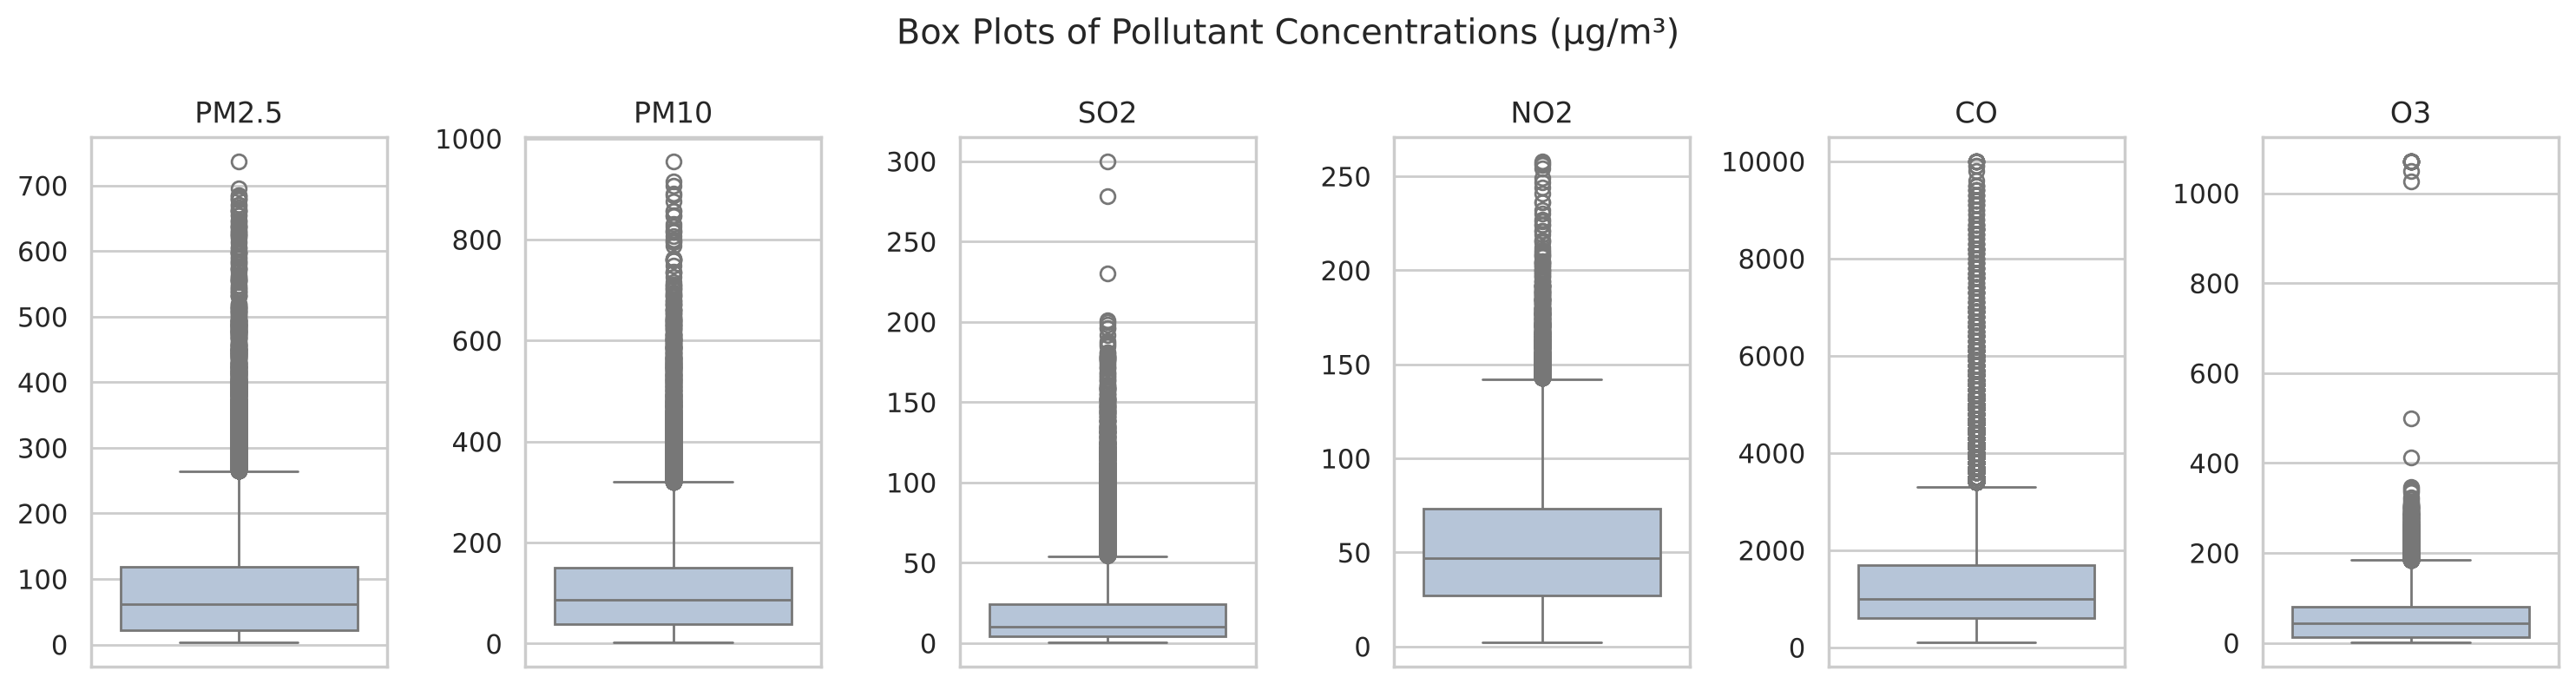

In [7]:
pollutants = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
fig, axes = plt.subplots(1, 6, figsize=(15, 4))
for ax, col in zip(axes, pollutants):
    sns.boxplot(y=df[col], ax=ax, color="lightsteelblue")
    ax.set_title(col)
    ax.set_ylabel("")
fig.suptitle("Box Plots of Pollutant Concentrations (µg/m³)")
plt.tight_layout()
plt.show()

In [8]:
rows = []
for col in pollutants:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    rows.append([col, q1, q3, iqr, upper, (df[col] > upper).sum(), df[col].max()])

pd.DataFrame(rows, columns=["variable", "Q1", "Q3", "IQR", "upper_fence",
                            "n_outliers", "max"]).round(1)

,variable,Q1,Q3,IQR,upper_fence,n_outliers,max
0,PM2.5,22.0,119.0,97.0,264.5,1622,737.0
1,PM10,38.0,151.0,113.0,320.5,1335,955.0
2,SO2,4.0,24.0,20.0,54.0,2606,300.0
3,NO2,27.0,73.0,46.0,142.0,600,258.0
4,CO,600.0,1700.0,1100.0,3350.0,1976,10000.0
5,O3,12.0,81.0,69.0,184.5,1318,1071.0


In [9]:
high_o3 = df[df["O3"] > 400]
print("O3 readings above 400:", len(high_o3))
print("Dates:", sorted(set(high_o3.index.date)))
df.loc["2013-08-15 20:00":"2013-08-16 03:00", ["NO2", "O3", "TEMP"]]

O3 readings above 400: 18
Dates: [datetime.date(2013, 8, 15), datetime.date(2013, 8, 16), datetime.date(2013, 8, 17), datetime.date(2017, 1, 6)]


,NO2,O3,TEMP
datetime,,,
2013-08-15 20:00:00,35.0,104.5,31.1
2013-08-15 21:00:00,37.0,104.5,30.9
2013-08-15 22:00:00,45.0,2.0,30.7
2013-08-15 23:00:00,40.0,1071.0,29.5
2013-08-16 00:00:00,34.0,1071.0,27.2
2013-08-16 01:00:00,28.0,413.0,27.2
2013-08-16 02:00:00,19.0,1050.0,26.7
2013-08-16 03:00:00,30.0,NaN,26.6


In [10]:
# O3 jumps between 2 and 1071 within a few hours -> sensor error, mark as missing
df.loc[df["O3"] > 400, "O3"] = np.nan
print("O3 maximum after removing invalid readings:", df["O3"].max())

O3 maximum after removing invalid readings: 346.0


### 6. Handling missing values

In [11]:
num_cols = df.select_dtypes("number").columns
pm_before = df["PM2.5"].describe()

# numeric columns: time-based linear interpolation between neighbouring hours
df[num_cols] = df[num_cols].interpolate(method="time")
# wind direction (categorical): carry the last observed direction forward
df["wd"] = df["wd"].ffill()

print("Missing values left:", df.isna().sum().sum())
pd.DataFrame({"PM2.5 before": pm_before, "PM2.5 after": df["PM2.5"].describe()}).round(2)

Missing values left: 0


,PM2.5 before,PM2.5 after
count,34314.00,35064.00
mean,86.19,86.14
std,86.58,86.26
min,3.00,3.00
25%,22.00,23.00
50%,61.00,61.00
75%,119.00,119.00
max,737.00,737.00


### 7. Univariate analysis

In [12]:
key = ["PM2.5", "PM10", "NO2", "CO", "O3", "TEMP", "DEWP", "WSPM"]
stats = df[key].describe().T
stats["skewness"] = df[key].skew()
stats["kurtosis"] = df[key].kurt()
stats.round(2)

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
PM2.5,35064.0,86.14,86.26,3.00,23.0,61.0,119.0,737.0,1.99,5.71
PM10,35064.0,110.35,98.24,2.00,38.0,86.0,150.0,955.0,1.96,6.28
NO2,35064.0,53.95,34.21,2.00,27.0,47.0,74.0,258.0,1.01,1.10
CO,35064.0,1331.91,1169.04,100.00,600.0,1000.0,1700.0,10000.0,2.52,9.34
O3,35064.0,57.23,54.07,0.64,13.0,45.0,82.0,346.0,1.33,1.68
TEMP,35064.0,13.67,11.46,-16.80,3.1,14.6,23.5,41.1,-0.10,-1.17
DEWP,35064.0,2.45,13.81,-35.30,-8.8,3.0,15.0,28.8,-0.20,-1.11
WSPM,35064.0,1.86,1.28,0.00,1.0,1.5,2.4,10.5,1.57,3.37


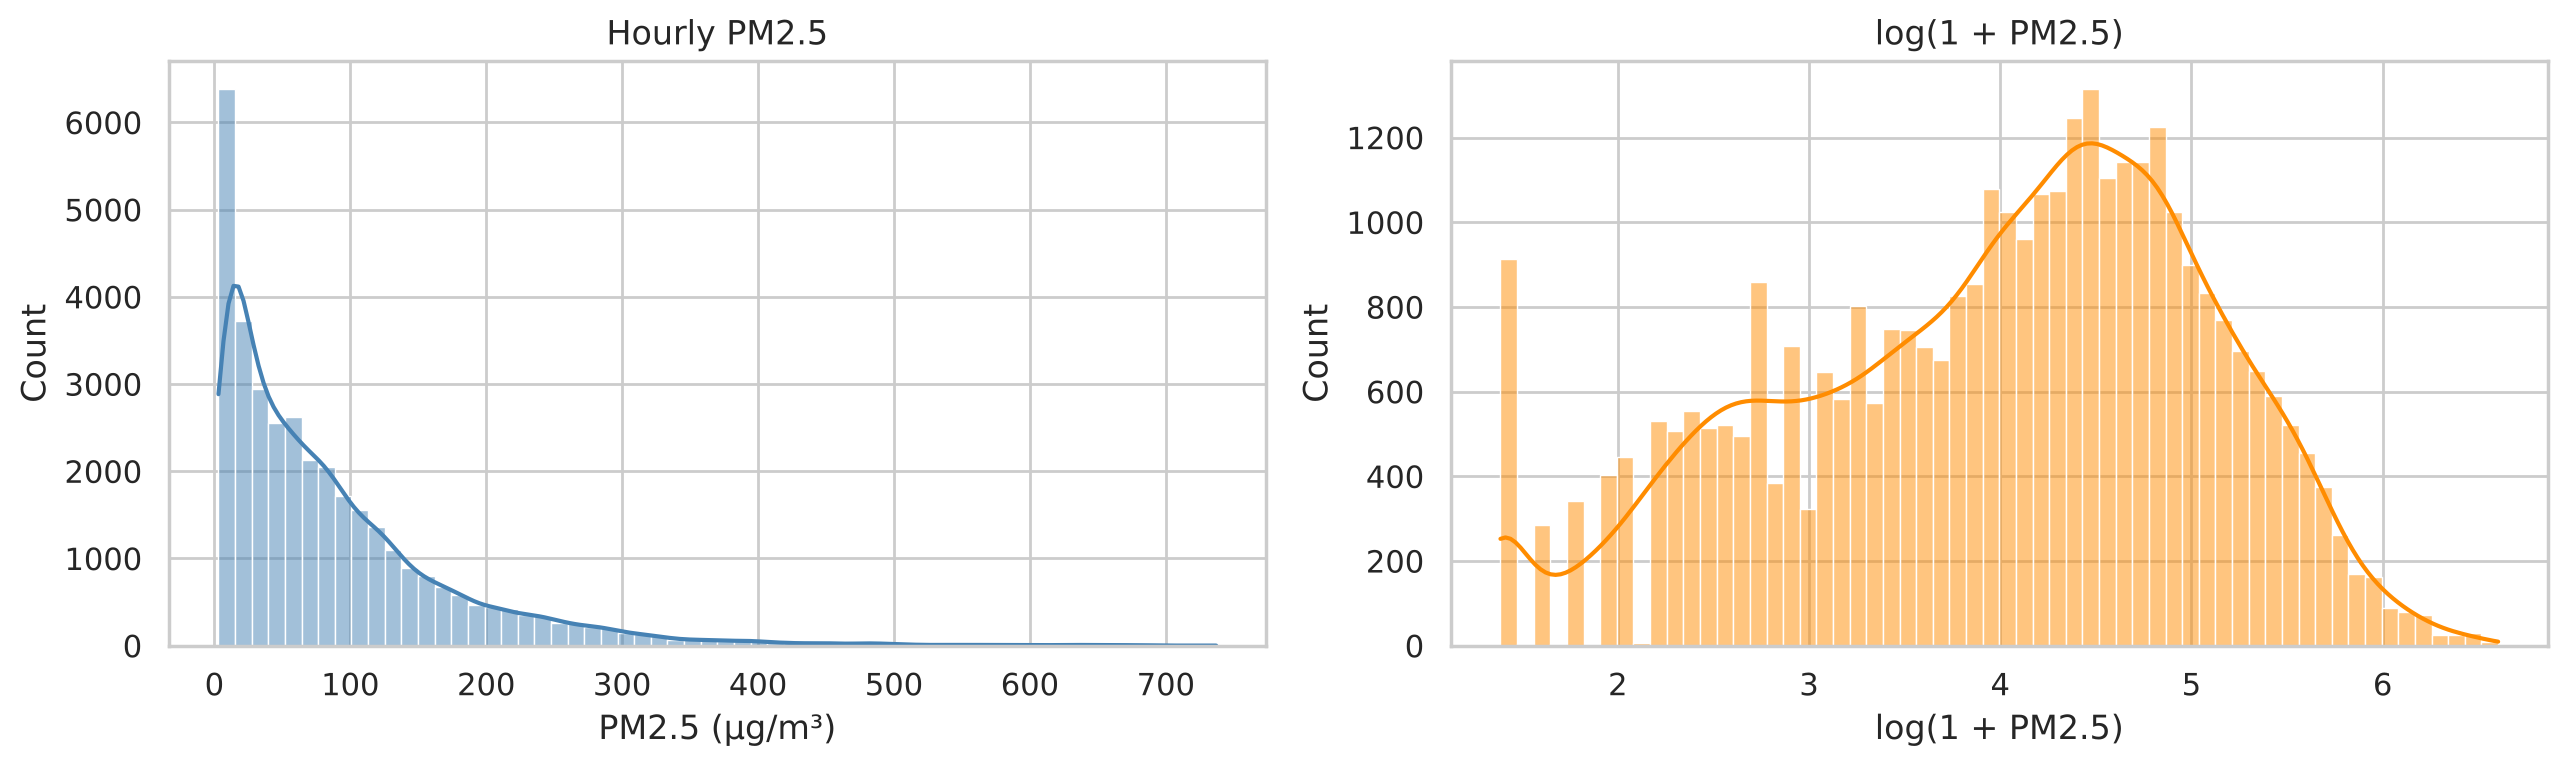

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["PM2.5"], bins=60, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Hourly PM2.5")
axes[0].set_xlabel("PM2.5 (µg/m³)")
sns.histplot(np.log1p(df["PM2.5"]), bins=60, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("log(1 + PM2.5)")
axes[1].set_xlabel("log(1 + PM2.5)")
plt.tight_layout()
plt.show()

In [14]:
# daily average and China's AQI levels for 24-hour PM2.5
daily = df.resample("D").mean(numeric_only=True)

bins = [0, 35, 75, 115, 150, 250, np.inf]
levels = ["Excellent", "Good", "Lightly polluted", "Moderately polluted",
          "Heavily polluted", "Severely polluted"]
daily["aqi_level"] = pd.cut(daily["PM2.5"], bins=bins, labels=levels)

freq = daily["aqi_level"].value_counts().reindex(levels)
aqi_table = pd.DataFrame({"days": freq, "percent": (freq / len(daily) * 100).round(1)})
print("Number of days:", len(daily))
aqi_table

Number of days: 1461


,days,percent
aqi_level,,
Excellent,399,27.3
Good,426,29.2
Lightly polluted,271,18.5
Moderately polluted,157,10.7
Heavily polluted,144,9.9
Severely polluted,64,4.4


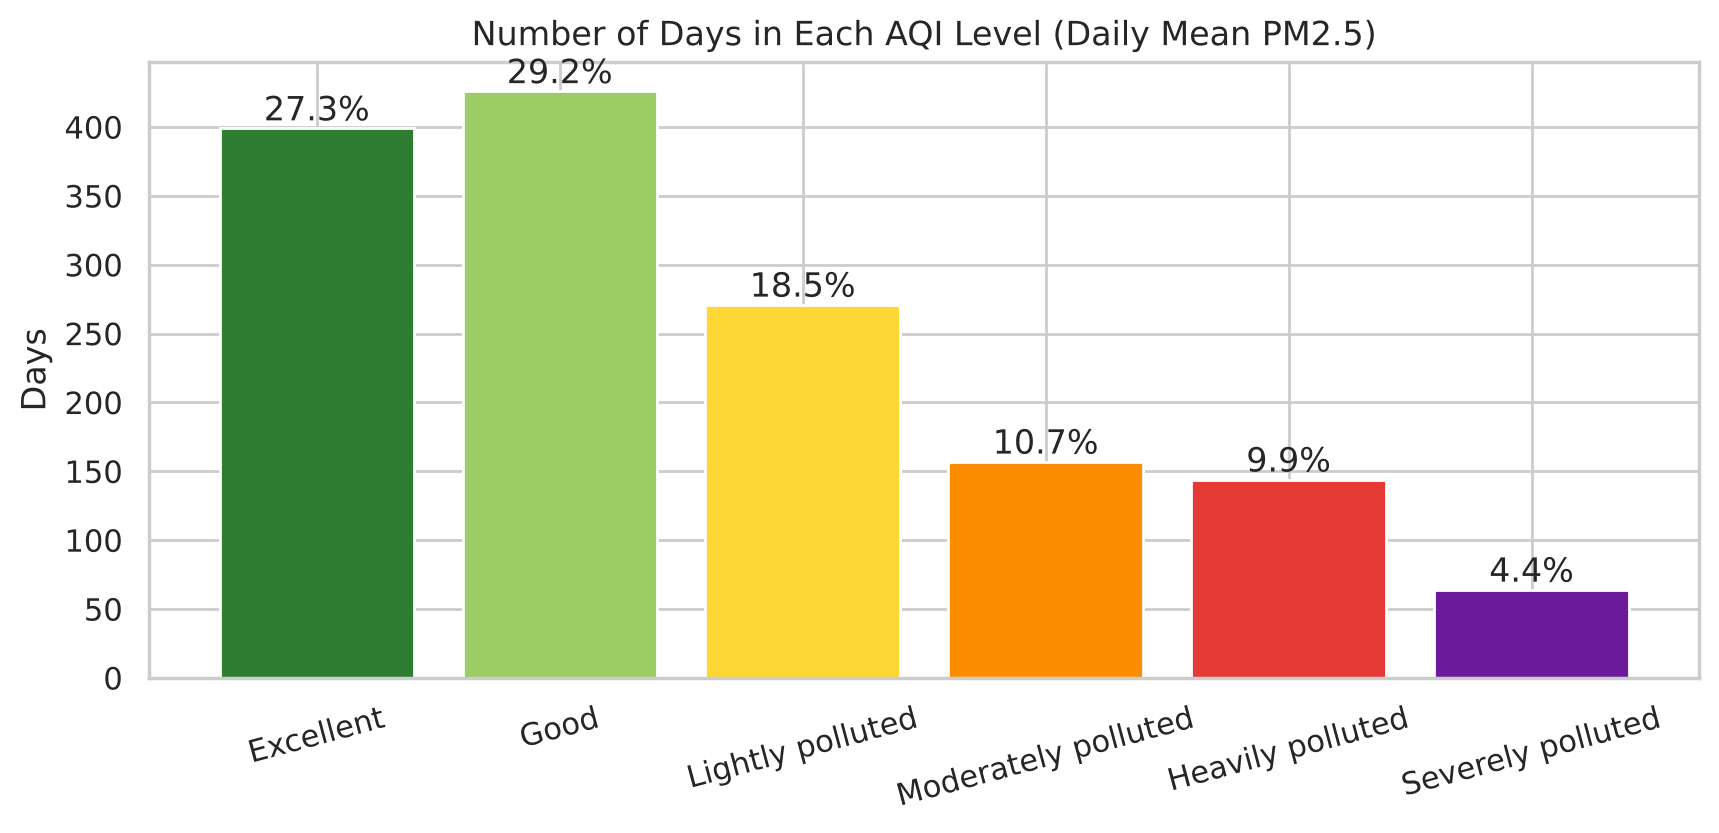

In [15]:
colors = ["#2e7d32", "#9ccc65", "#fdd835", "#fb8c00", "#e53935", "#6a1b9a"]
plt.figure(figsize=(10, 4))
bars = plt.bar(aqi_table.index, aqi_table["days"], color=colors)
plt.bar_label(bars, labels=[f"{p}%" for p in aqi_table["percent"]])
plt.title("Number of Days in Each AQI Level (Daily Mean PM2.5)")
plt.ylabel("Days")
plt.xticks(rotation=15)
plt.show()

### 8. Bivariate analysis: when and why is PM2.5 high?

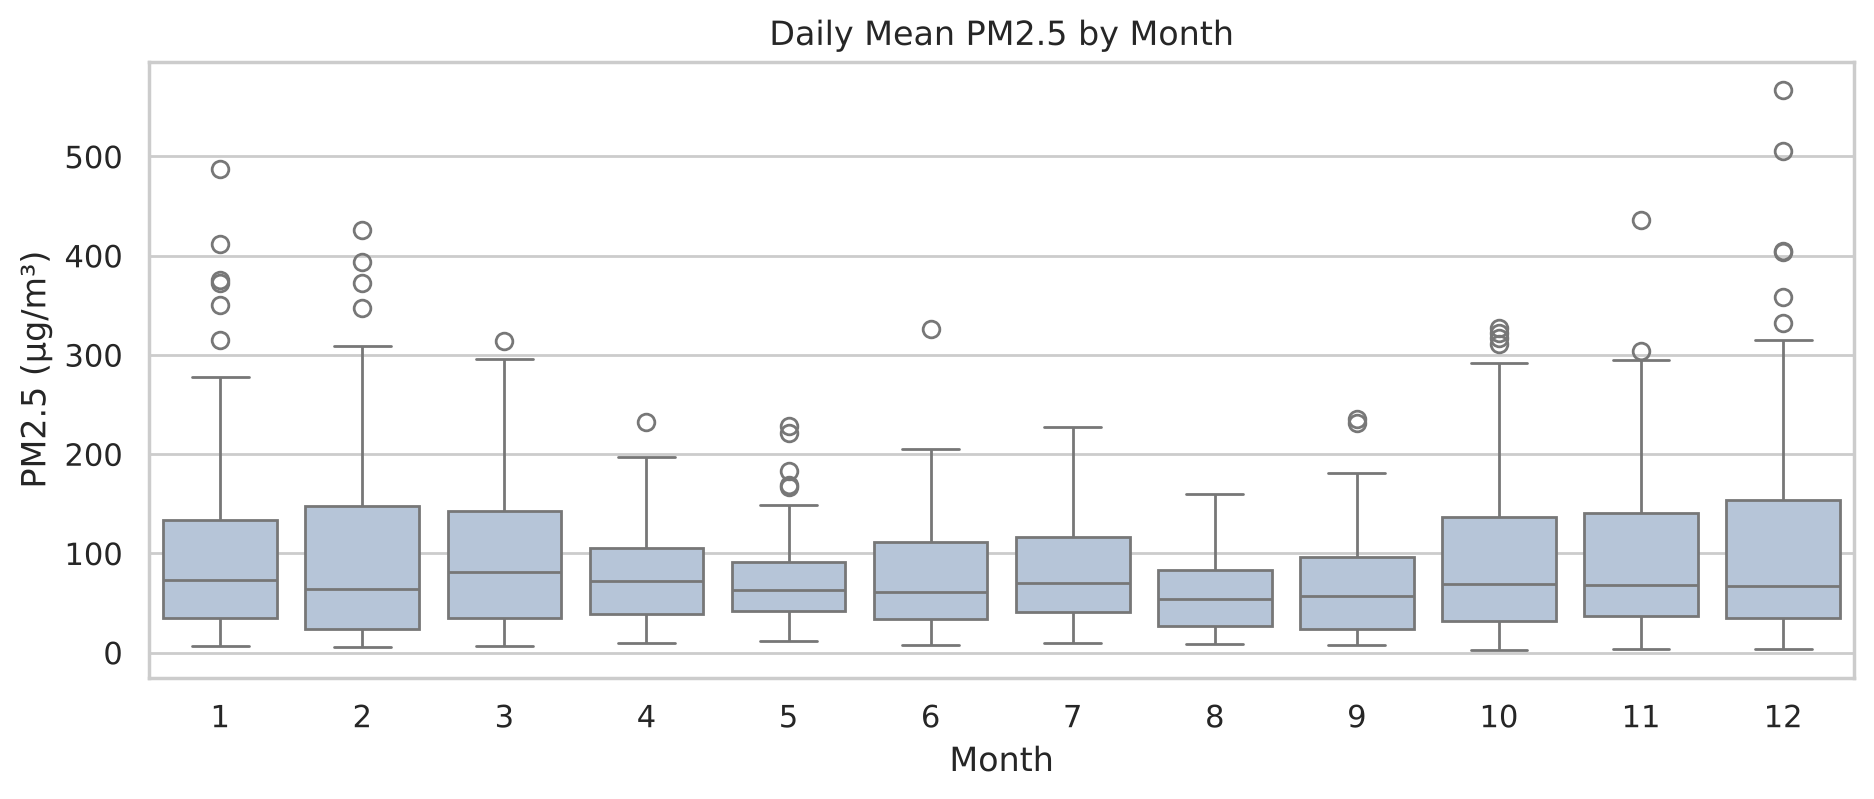

,mean,median,std,max
season,,,,
Autumn,88.2,65.3,75.3,435.6
Spring,82.4,71.5,59.7,313.9
Summer,71.2,61.8,46.5,325.7
Winter,103.1,67.6,99.8,567.4


In [16]:
season_map = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
              6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
daily["month"] = daily.index.month
daily["season"] = daily["month"].map(season_map)

plt.figure(figsize=(11, 4))
sns.boxplot(data=daily, x="month", y="PM2.5", color="lightsteelblue")
plt.title("Daily Mean PM2.5 by Month")
plt.xlabel("Month")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

daily.groupby("season")["PM2.5"].agg(["mean", "median", "std", "max"]).round(1)

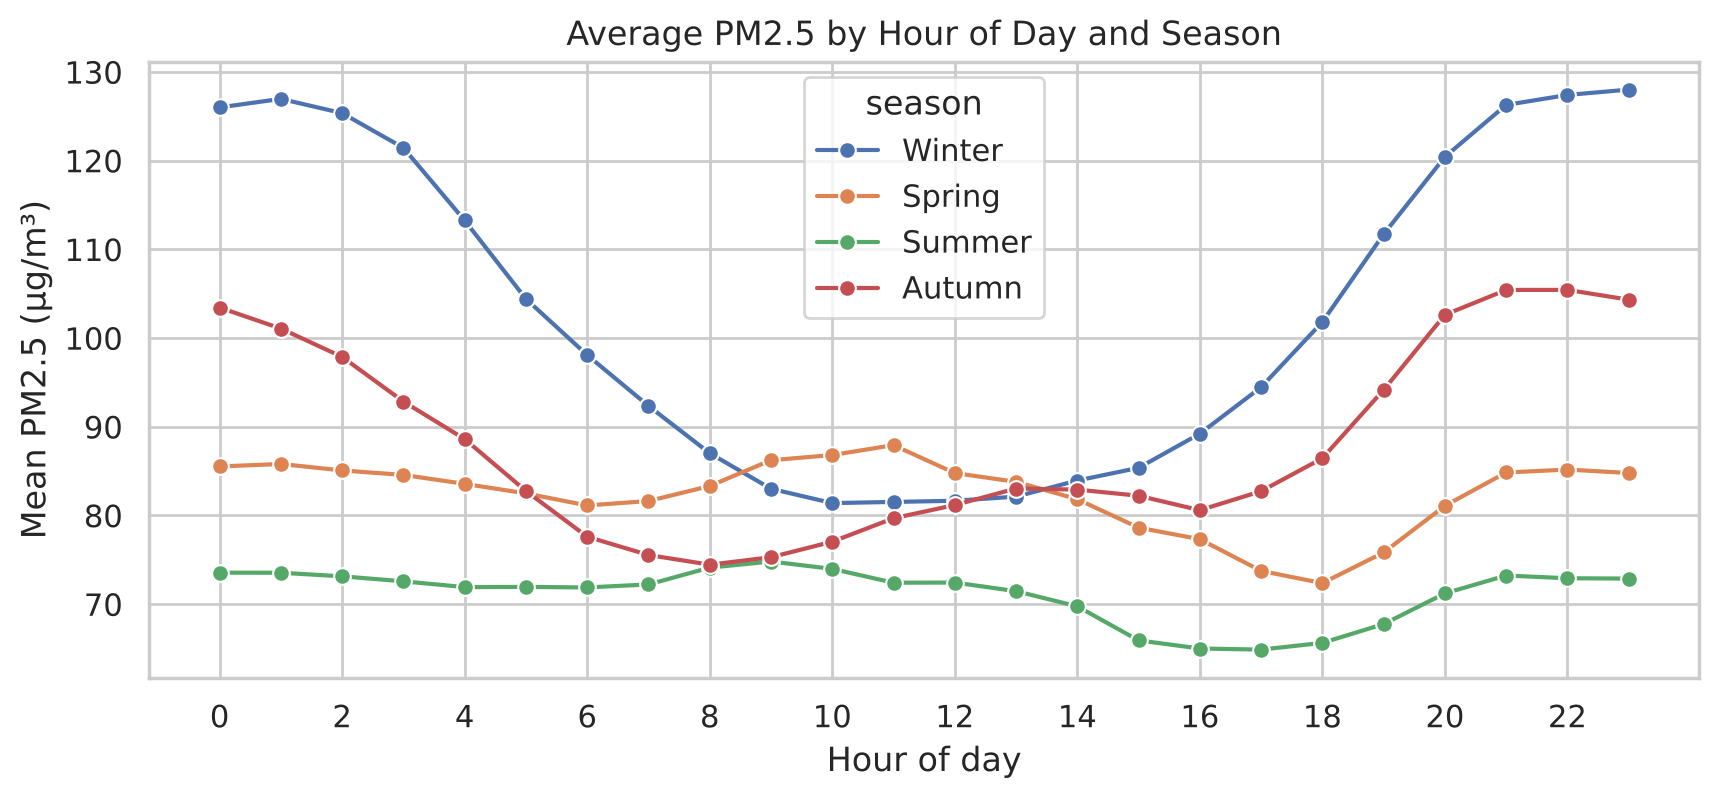

In [17]:
df["hour"] = df.index.hour
df["season"] = df.index.month.map(season_map)

hourly_profile = df.groupby(["season", "hour"])["PM2.5"].mean().reset_index()
plt.figure(figsize=(10, 4))
sns.lineplot(data=hourly_profile, x="hour", y="PM2.5", hue="season",
             hue_order=["Winter", "Spring", "Summer", "Autumn"], marker="o")
plt.title("Average PM2.5 by Hour of Day and Season")
plt.xlabel("Hour of day")
plt.ylabel("Mean PM2.5 (µg/m³)")
plt.xticks(range(0, 24, 2))
plt.show()

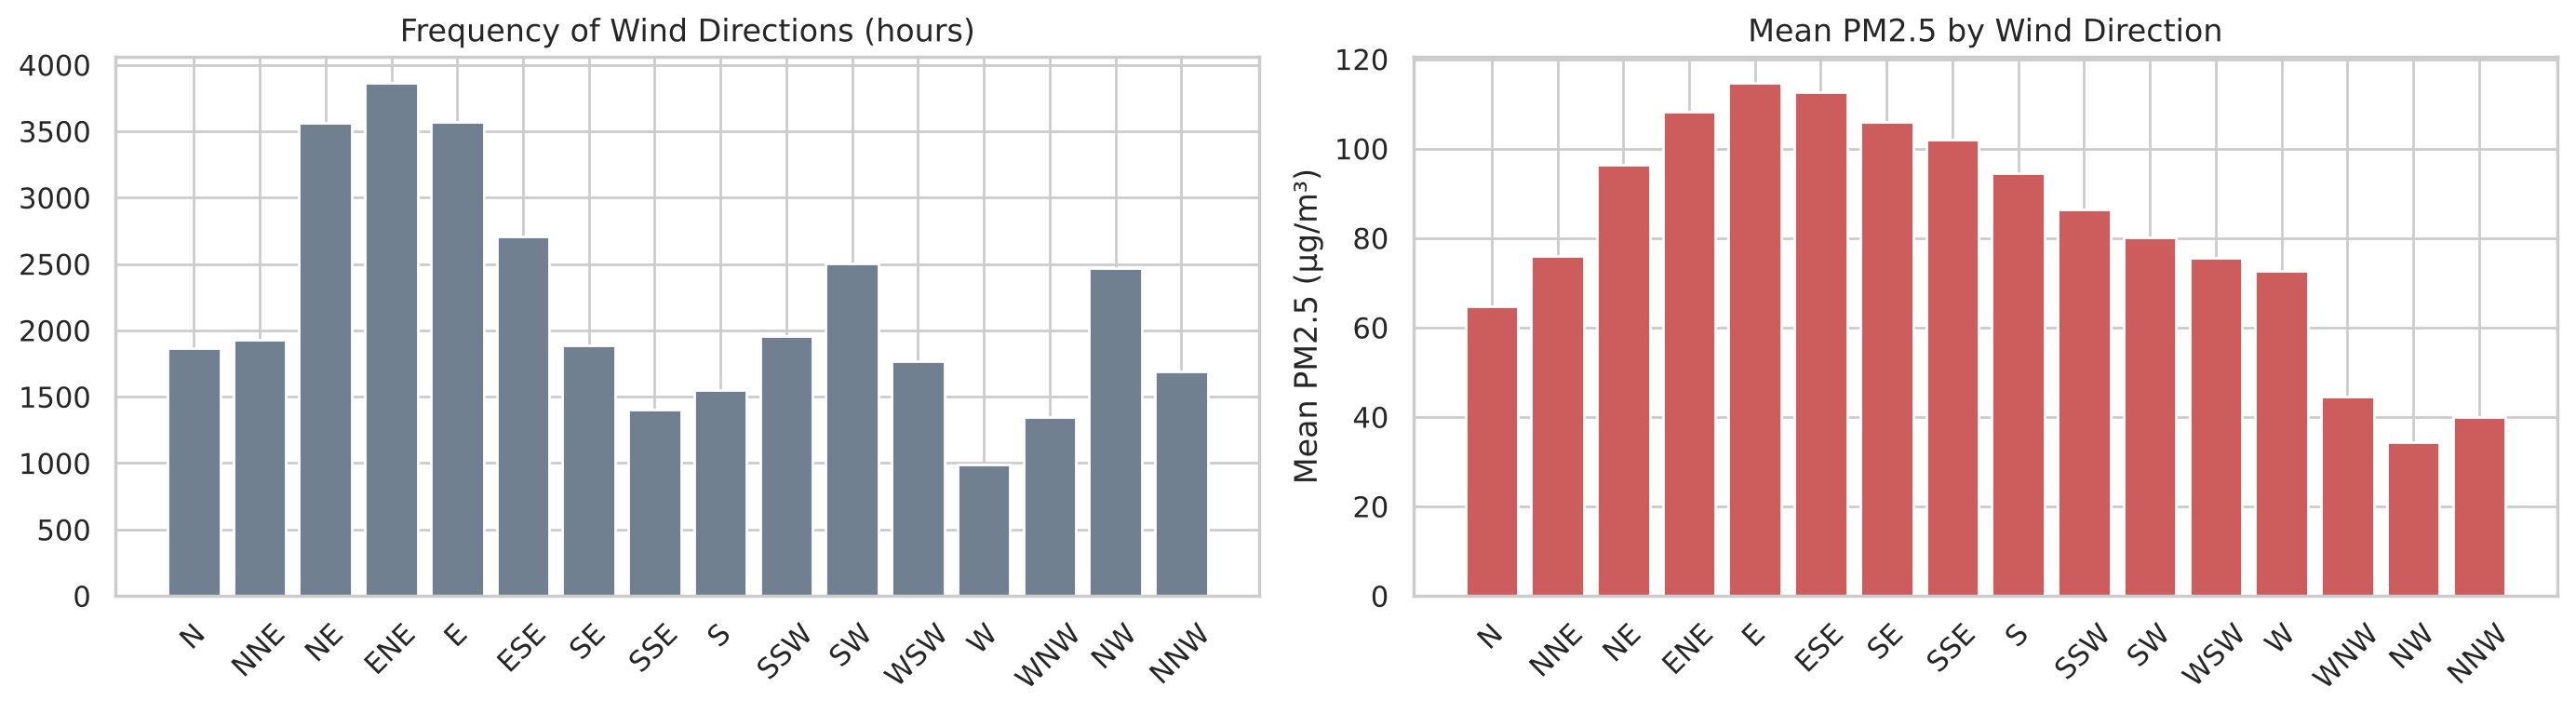

In [18]:
compass = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
           "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
wind = df.groupby("wd")["PM2.5"].agg(["count", "mean"]).reindex(compass)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(wind.index, wind["count"], color="slategray")
axes[0].set_title("Frequency of Wind Directions (hours)")
axes[1].bar(wind.index, wind["mean"], color="indianred")
axes[1].set_title("Mean PM2.5 by Wind Direction")
axes[1].set_ylabel("Mean PM2.5 (µg/m³)")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

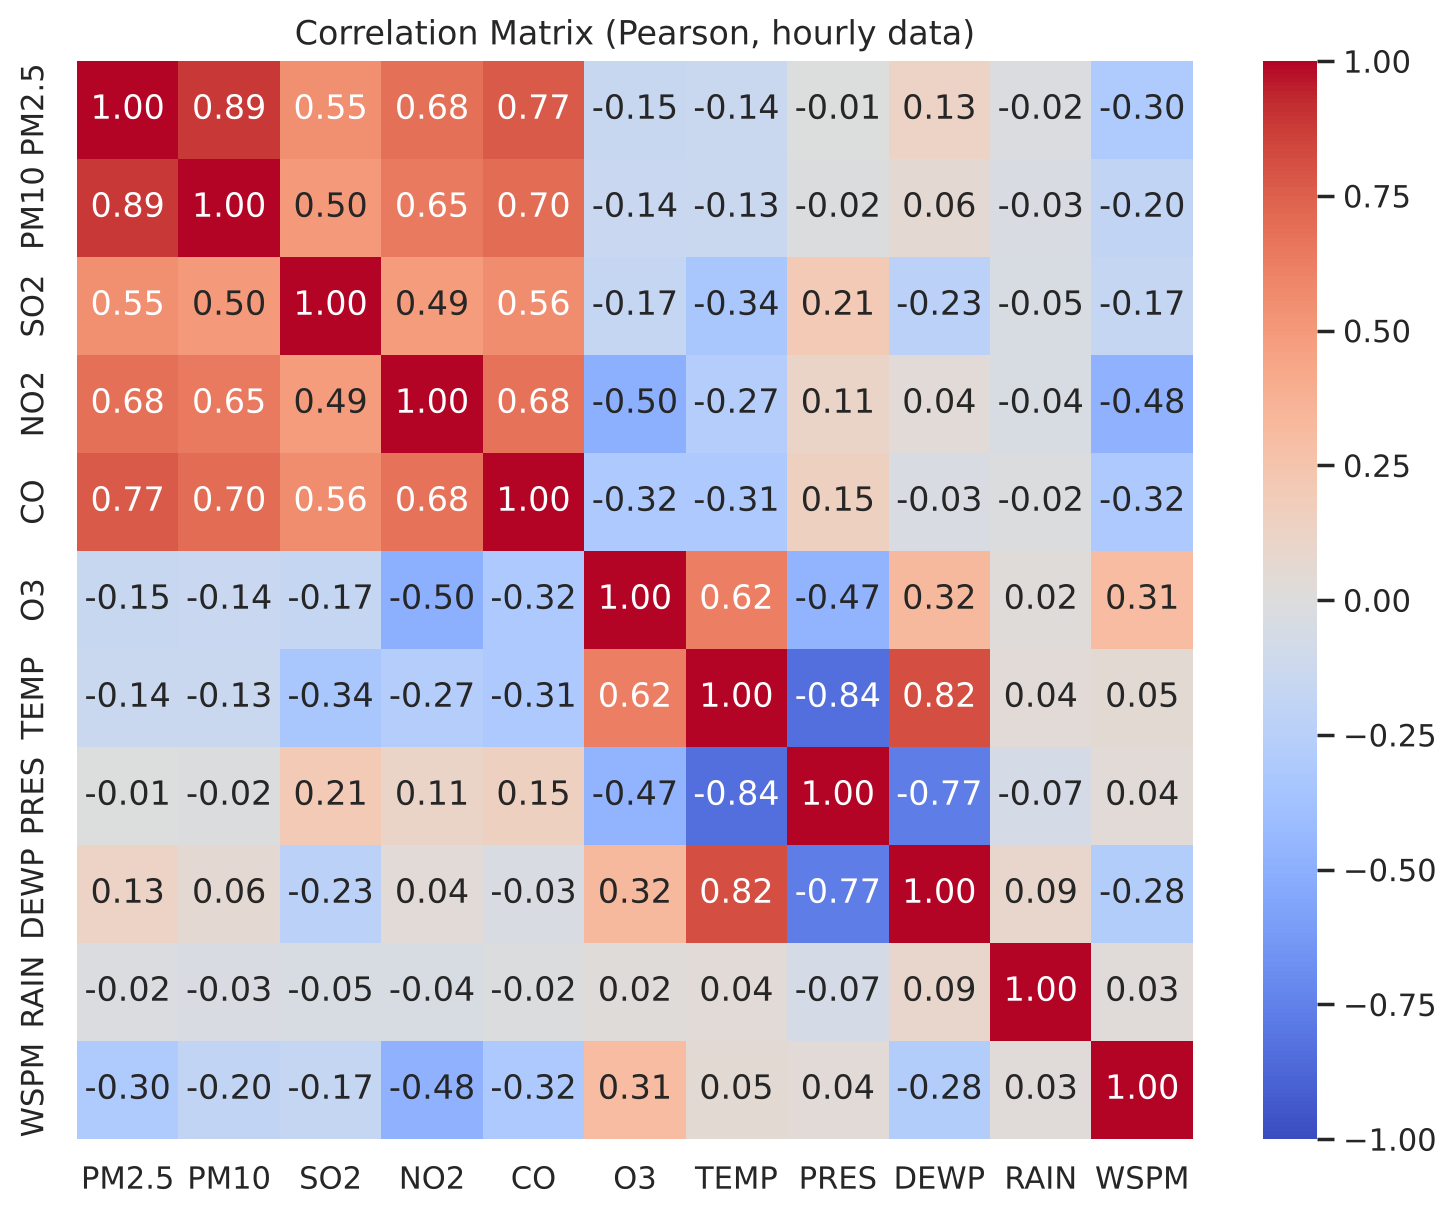

In [19]:
corr = df[["PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
           "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix (Pearson, hourly data)")
plt.show()

### 9. Multivariate analysis

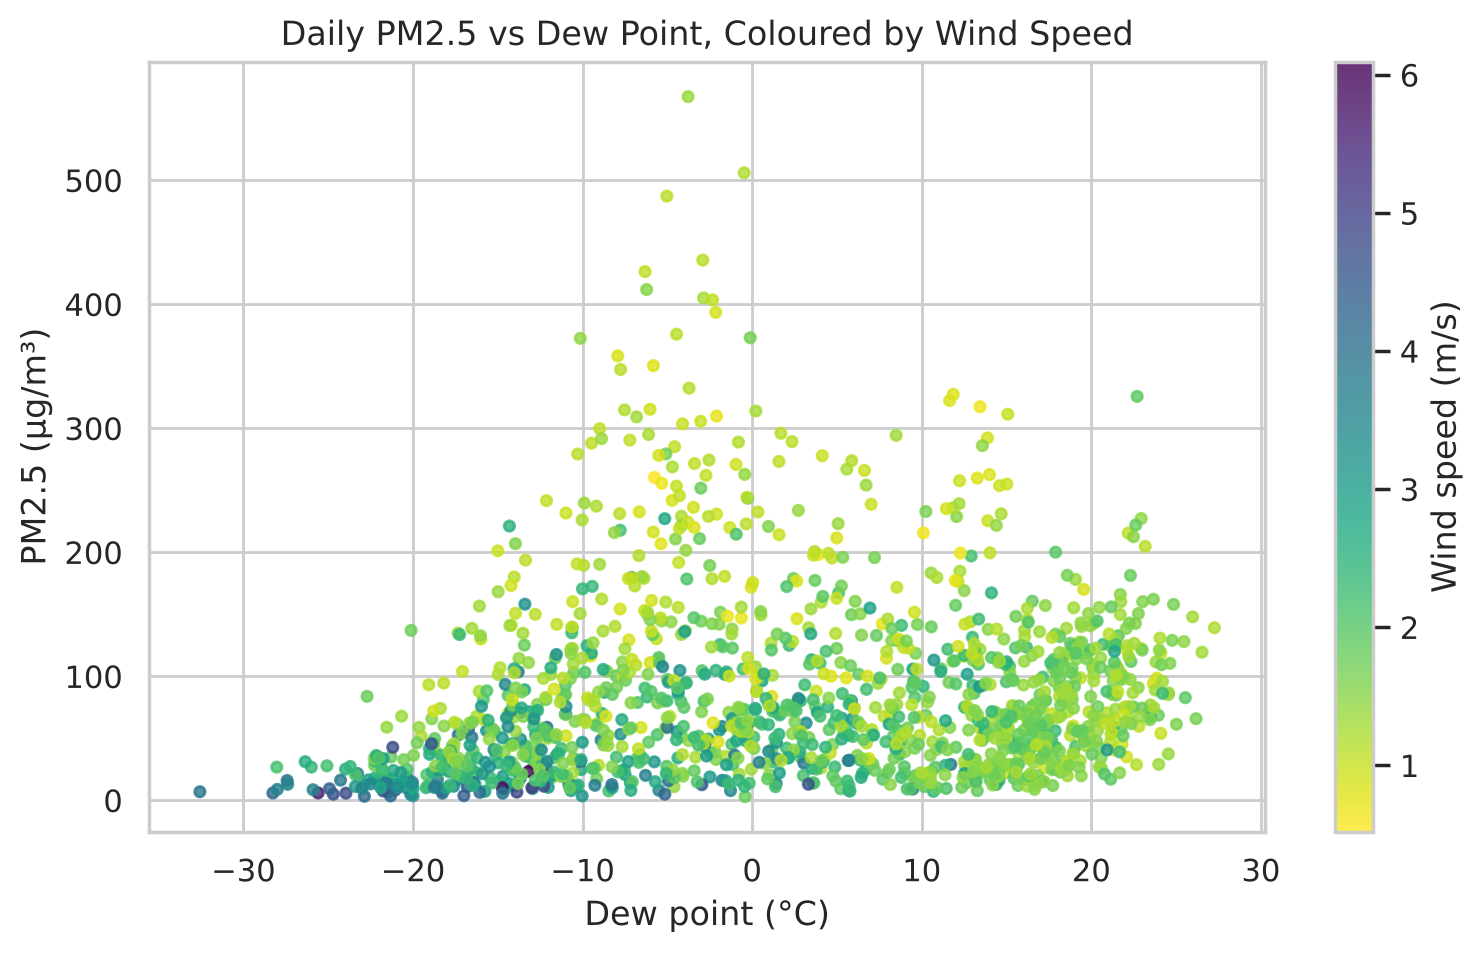

In [20]:
plt.figure(figsize=(9, 5))
sc = plt.scatter(daily["DEWP"], daily["PM2.5"], c=daily["WSPM"],
                 cmap="viridis_r", s=14, alpha=0.8)
plt.colorbar(sc, label="Wind speed (m/s)")
plt.title("Daily PM2.5 vs Dew Point, Coloured by Wind Speed")
plt.xlabel("Dew point (°C)")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

### 10. Time series analysis

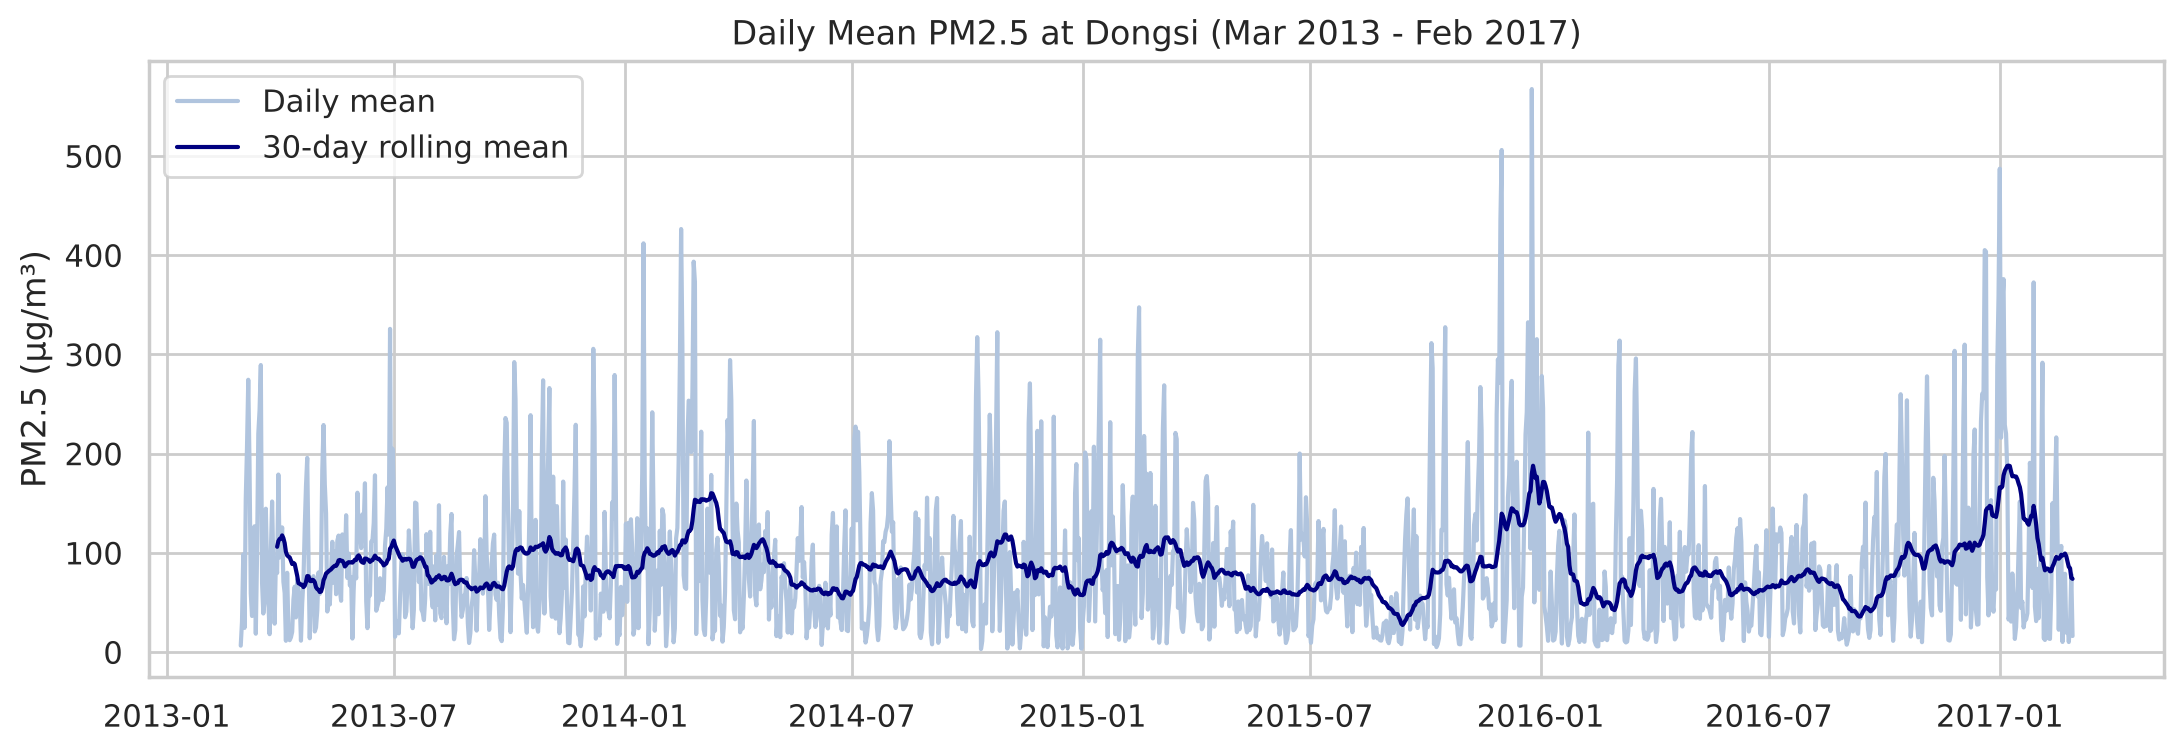

In [21]:
plt.figure(figsize=(13, 4))
plt.plot(daily.index, daily["PM2.5"], color="lightsteelblue", label="Daily mean")
plt.plot(daily.index, daily["PM2.5"].rolling(30).mean(), color="navy", label="30-day rolling mean")
plt.title("Daily Mean PM2.5 at Dongsi (Mar 2013 - Feb 2017)")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.show()

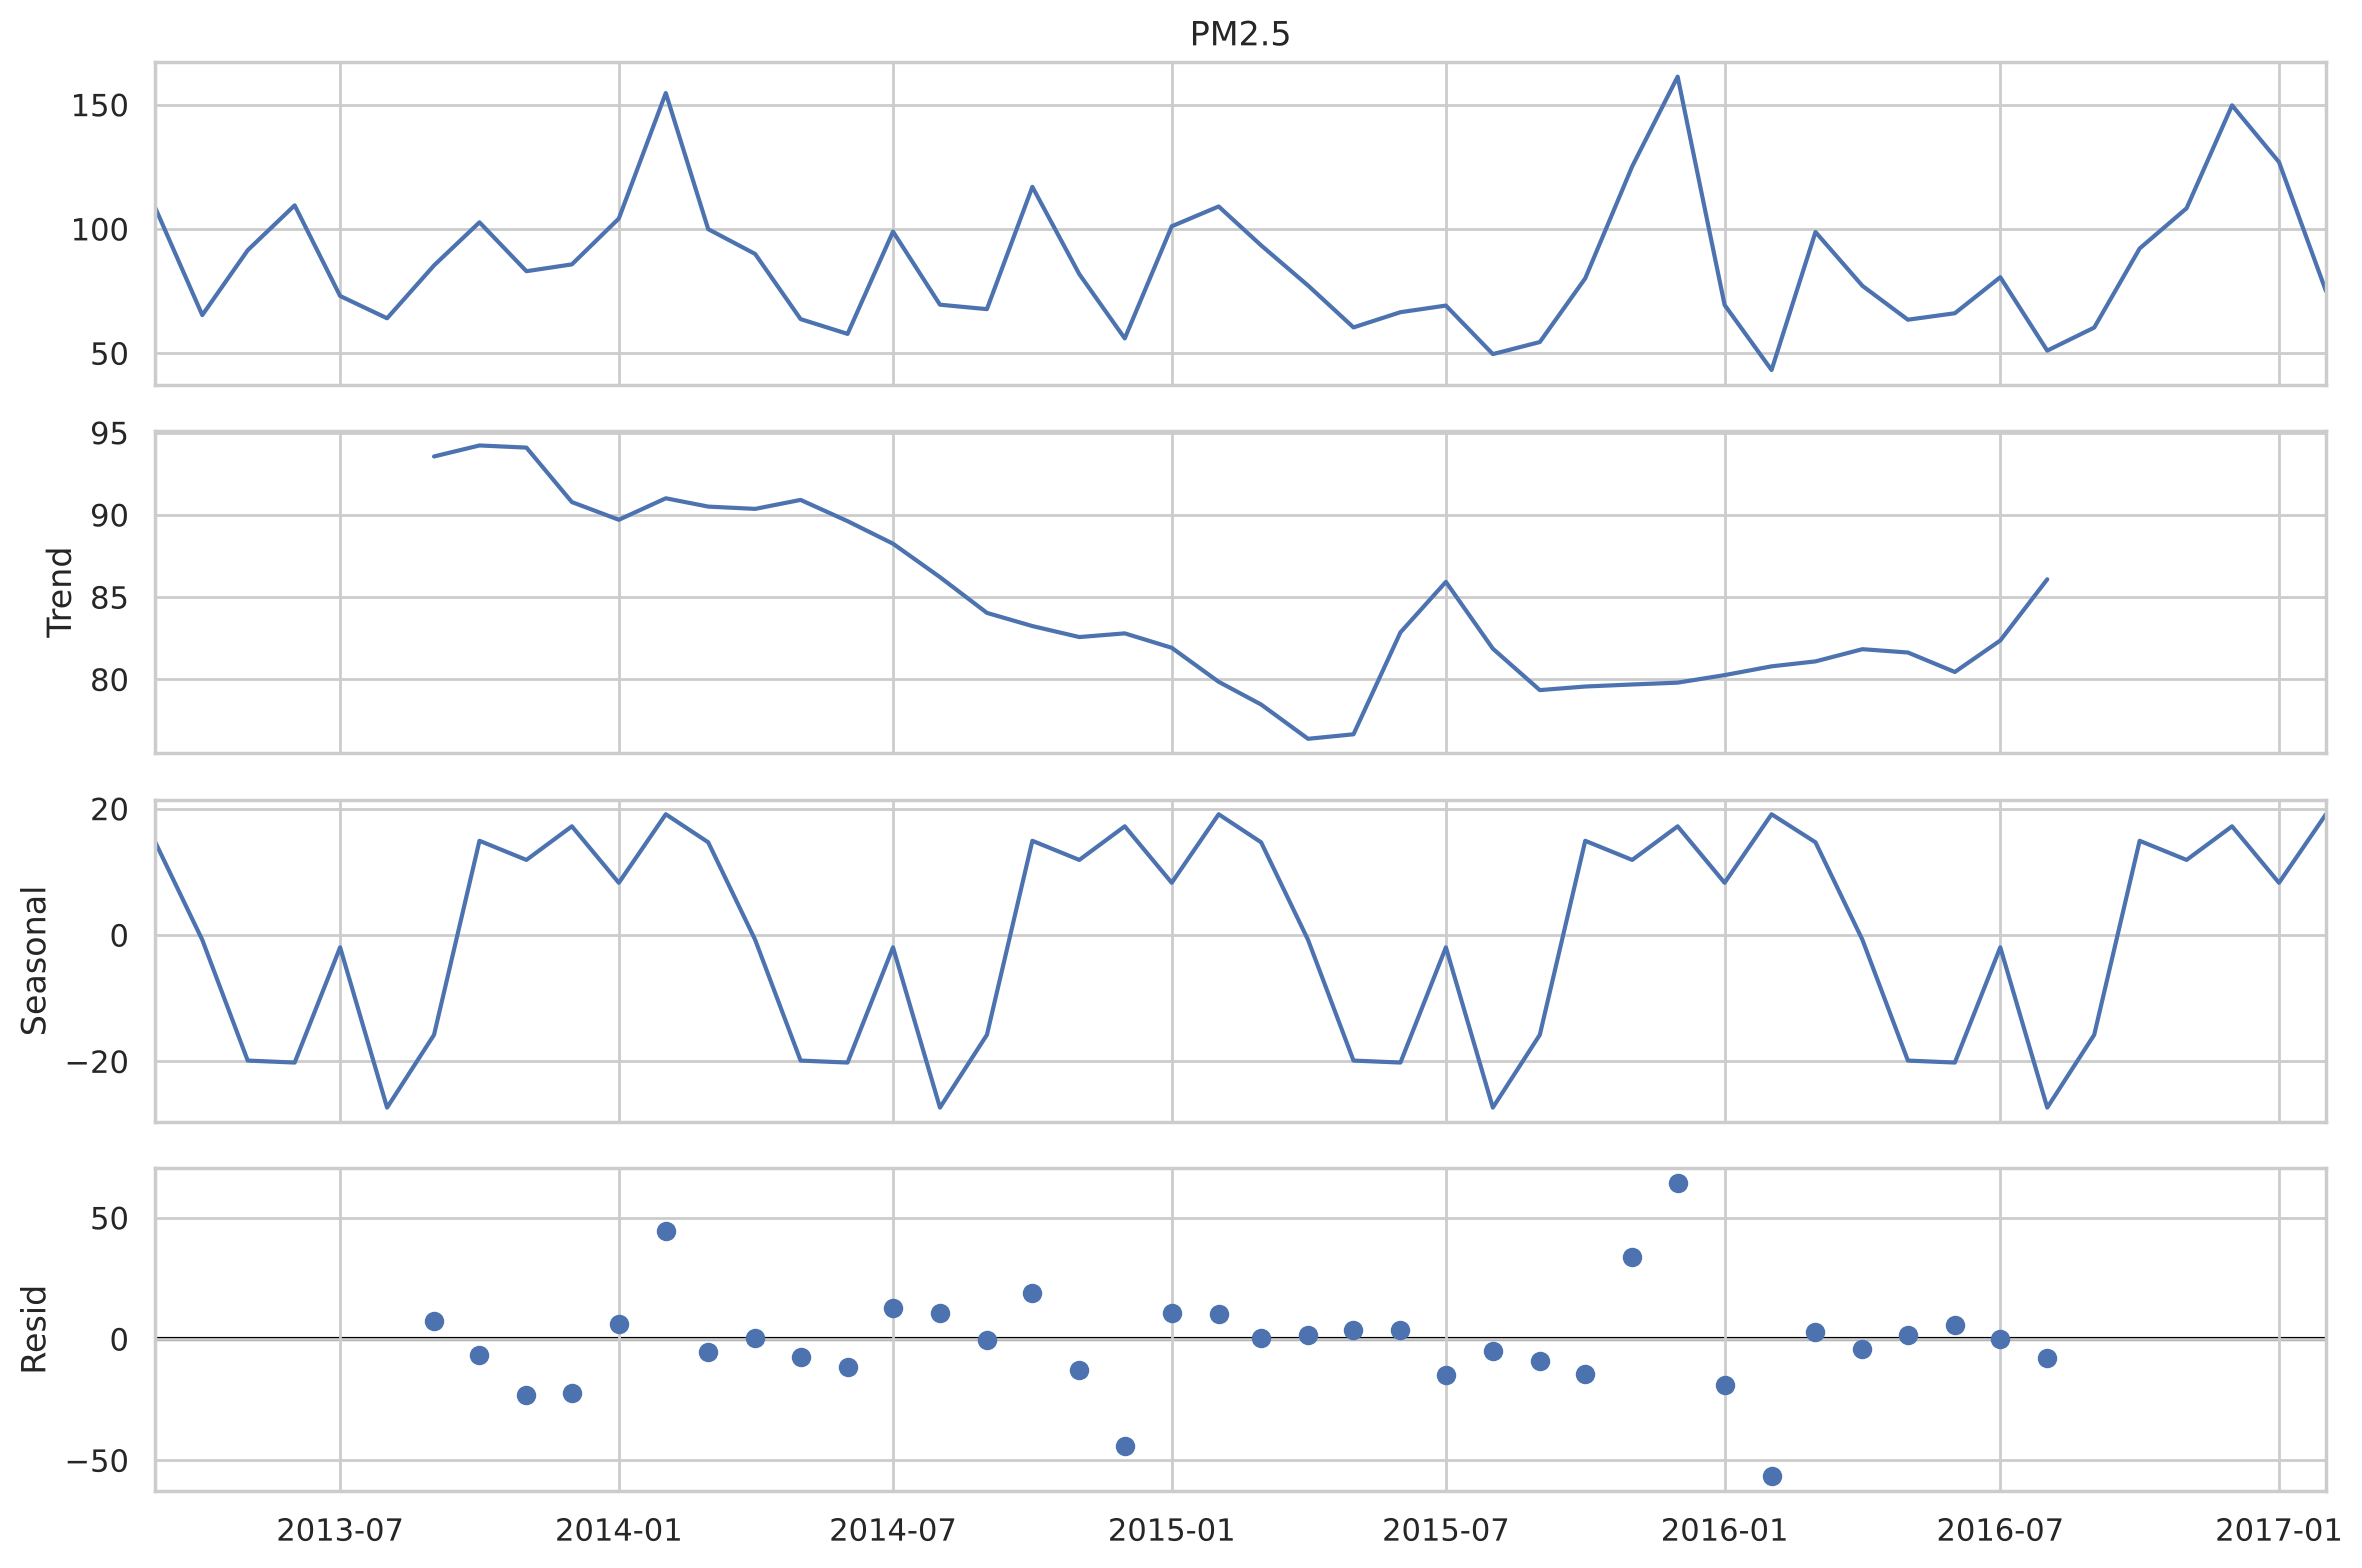

datetime
1      8.3
2     19.1
3     14.7
4     -0.8
5    -19.9
6    -20.2
7     -2.0
8    -27.3
9    -15.8
10    14.9
11    11.9
12    17.2
Name: seasonal, dtype: float64

In [22]:
from statsmodels.tsa.seasonal import seasonal_decompose

monthly = daily["PM2.5"].resample("MS").mean()
decomp = seasonal_decompose(monthly, model="additive", period=12)
fig = decomp.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

# seasonal effect for each calendar month (µg/m³ above / below the trend)
decomp.seasonal.groupby(decomp.seasonal.index.month).first().round(1)

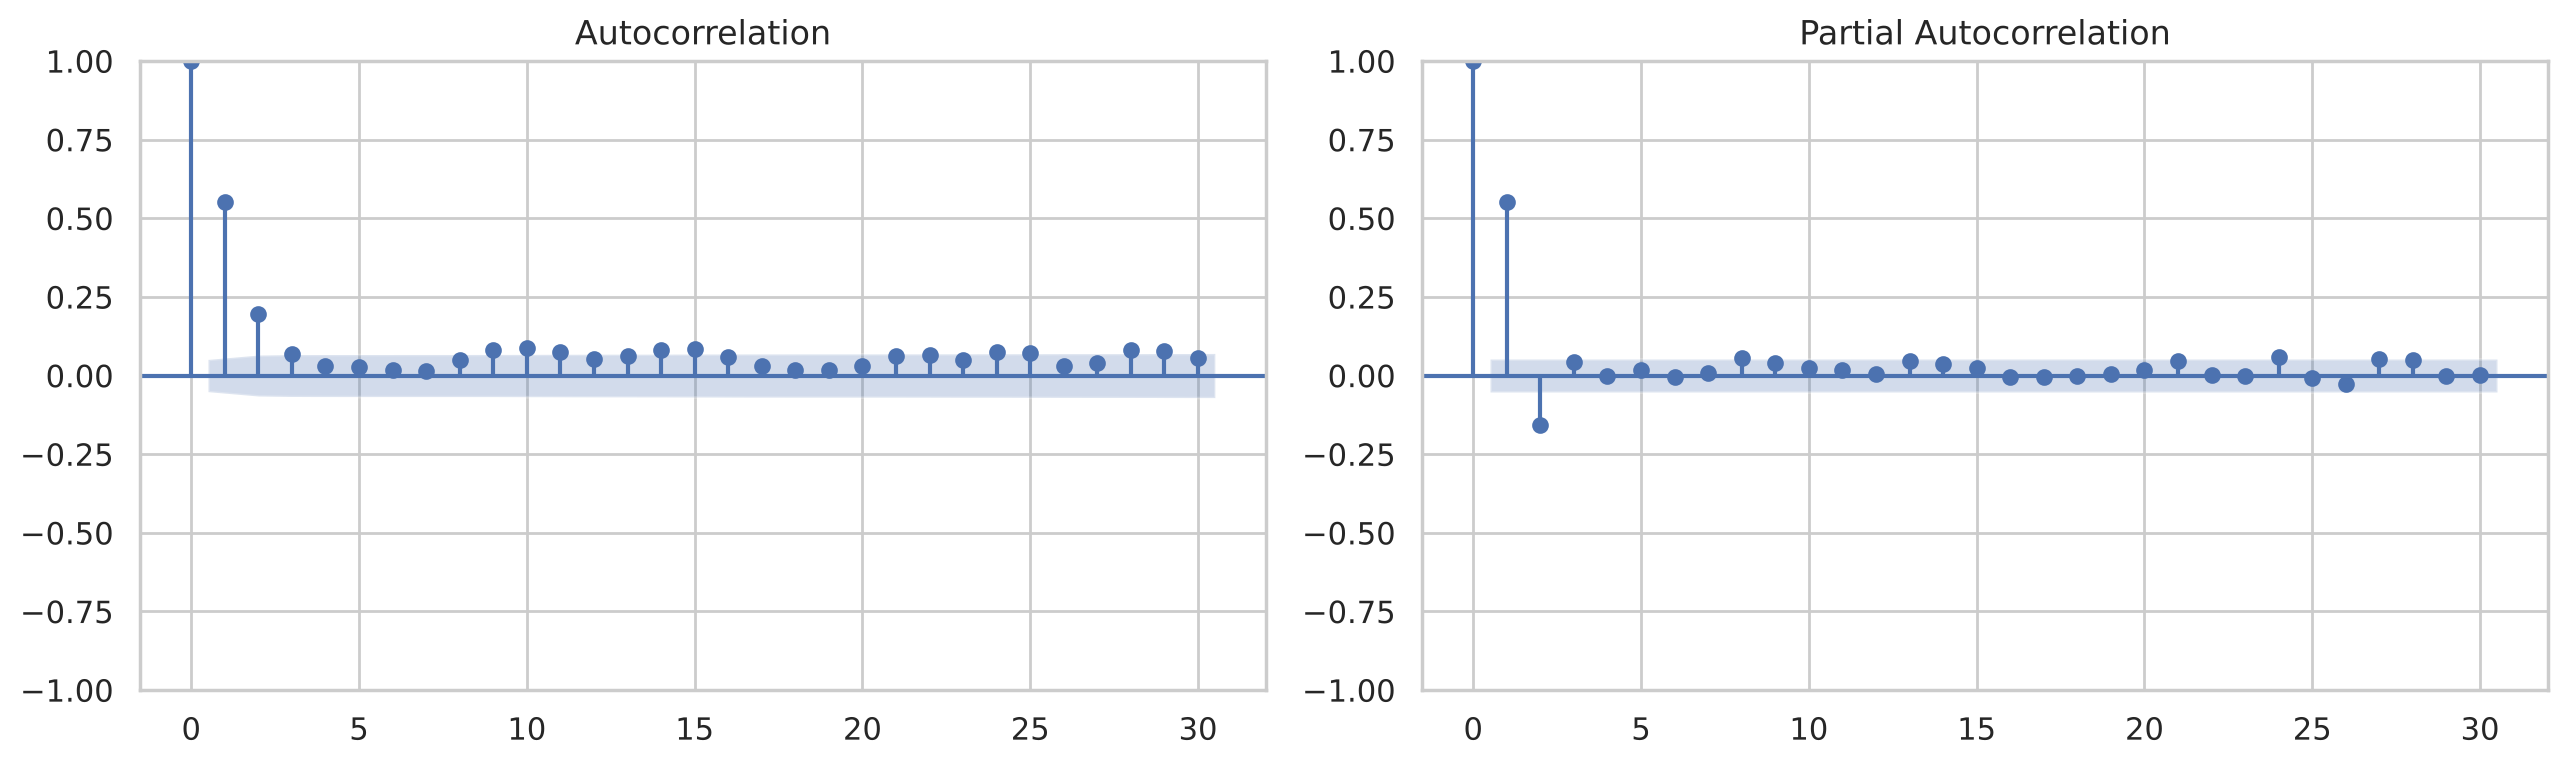

In [23]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(daily["PM2.5"], lags=30, ax=axes[0])
plot_pacf(daily["PM2.5"], lags=30, ax=axes[1])
plt.tight_layout()
plt.show()

### 11. Forecasting model: next-day PM2.5

In [24]:
# target = tomorrow's daily mean PM2.5
data = pd.DataFrame(index=daily.index)
data["pm_today"] = daily["PM2.5"]
data["pm_yesterday"] = daily["PM2.5"].shift(1)
data["pm_7day_mean"] = daily["PM2.5"].rolling(7).mean()
data["month"] = daily.index.month
# tomorrow's weather (in practice taken from a weather forecast)
for col in ["TEMP", "PRES", "DEWP", "WSPM", "RAIN"]:
    data[col + "_tomorrow"] = daily[col].shift(-1)
data["target"] = daily["PM2.5"].shift(-1)
data = data.dropna()

# chronological split: last 12 months are kept for testing
train = data[data.index < "2016-03-01"]
test = data[data.index >= "2016-03-01"]
features = [c for c in data.columns if c != "target"]
print("Features:", features)
print("Train:", train.index.min().date(), "to", train.index.max().date(), "-", len(train), "days")
print("Test :", test.index.min().date(), "to", test.index.max().date(), "-", len(test), "days")

Features: ['pm_today', 'pm_yesterday', 'pm_7day_mean', 'month', 'TEMP_tomorrow', 'PRES_tomorrow', 'DEWP_tomorrow', 'WSPM_tomorrow', 'RAIN_tomorrow']
Train: 2013-03-07 to 2016-02-29 - 1090 days
Test : 2016-03-01 to 2017-02-27 - 364 days


In [25]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(name, y_true, y_pred):
    return {"model": name,
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

X_train, y_train = train[features], train["target"]
X_test, y_test = test[features], test["target"]

lr = LinearRegression().fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42)
rf.fit(X_train, y_train)

# same forest without tomorrow's weather, to measure how much the weather helps
history_only = ["pm_today", "pm_yesterday", "pm_7day_mean", "month"]
rf_hist = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42)
rf_hist.fit(train[history_only], y_train)

results = pd.DataFrame([
    evaluate("Baseline: tomorrow = today", y_test, test["pm_today"]),
    evaluate("Linear Regression", y_test, lr.predict(X_test)),
    evaluate("Random Forest", y_test, rf.predict(X_test)),
    evaluate("Random Forest (no weather)", y_test, rf_hist.predict(test[history_only])),
])
results.round(3)

,model,MAE,RMSE,R2
0,Baseline: tomorrow = today,47.905,70.362,0.175
1,Linear Regression,36.990,52.031,0.549
2,Random Forest,31.213,43.566,0.684
3,Random Forest (no weather),44.389,63.078,0.337


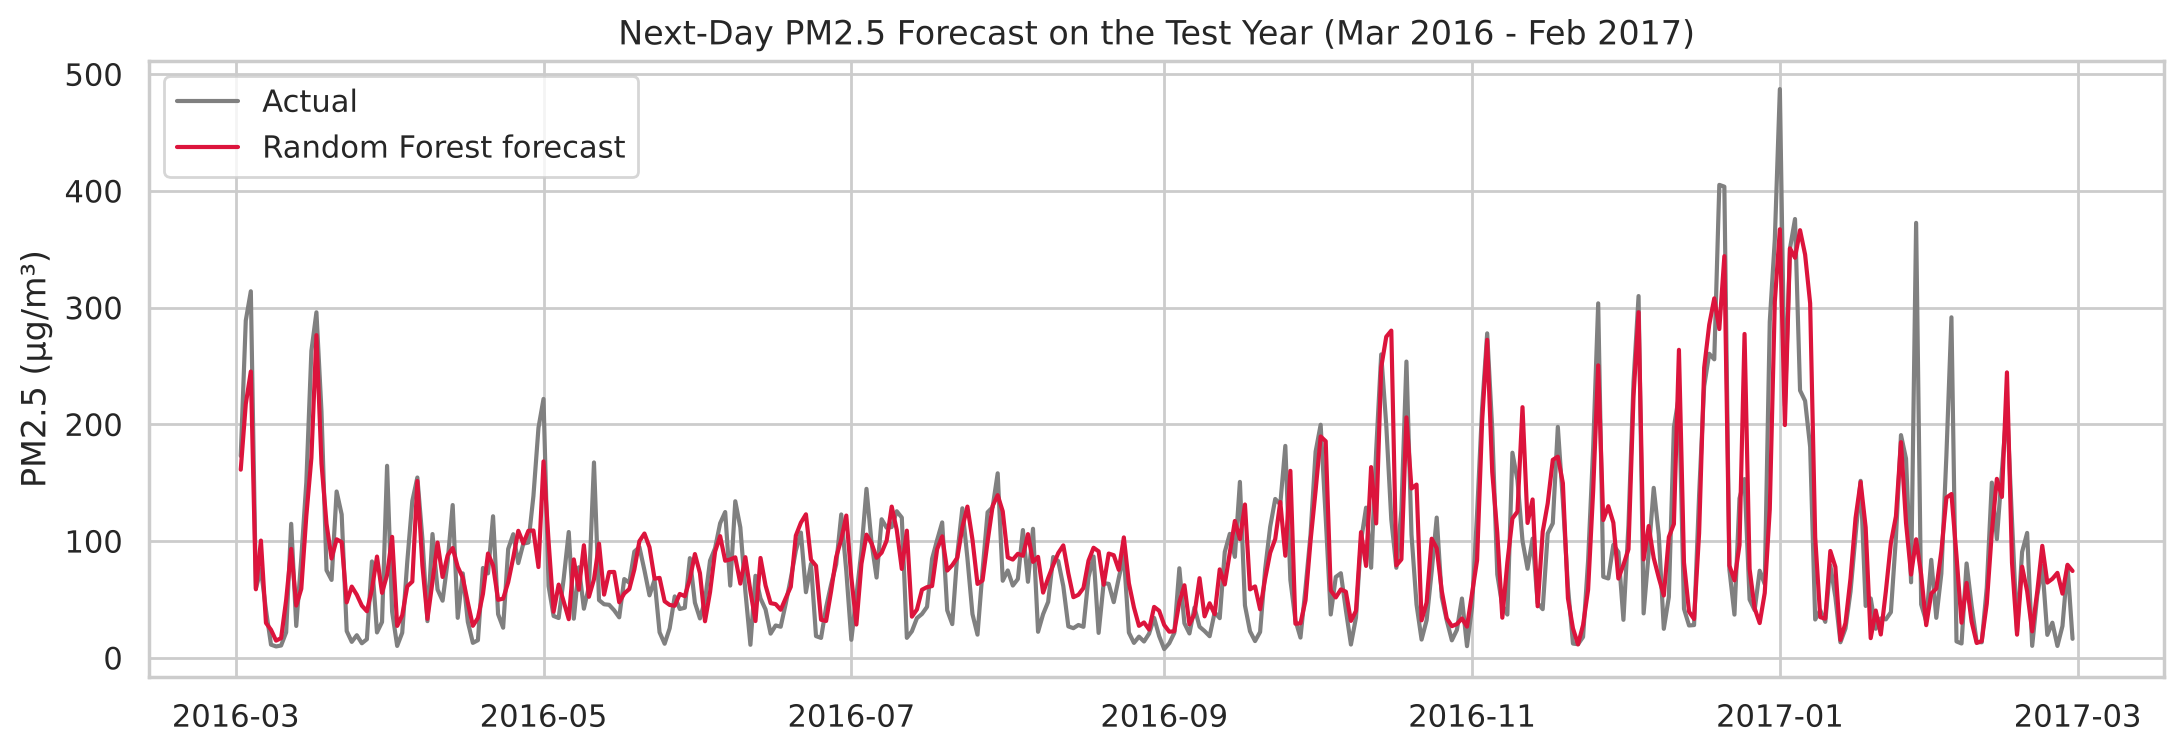

In [26]:
pred = pd.Series(rf.predict(X_test), index=X_test.index)
forecast_day = y_test.index + pd.Timedelta(days=1)   # the day each forecast is for

plt.figure(figsize=(13, 4))
plt.plot(forecast_day, y_test, color="gray", label="Actual")
plt.plot(forecast_day, pred, color="crimson", label="Random Forest forecast")
plt.title("Next-Day PM2.5 Forecast on the Test Year (Mar 2016 - Feb 2017)")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.show()

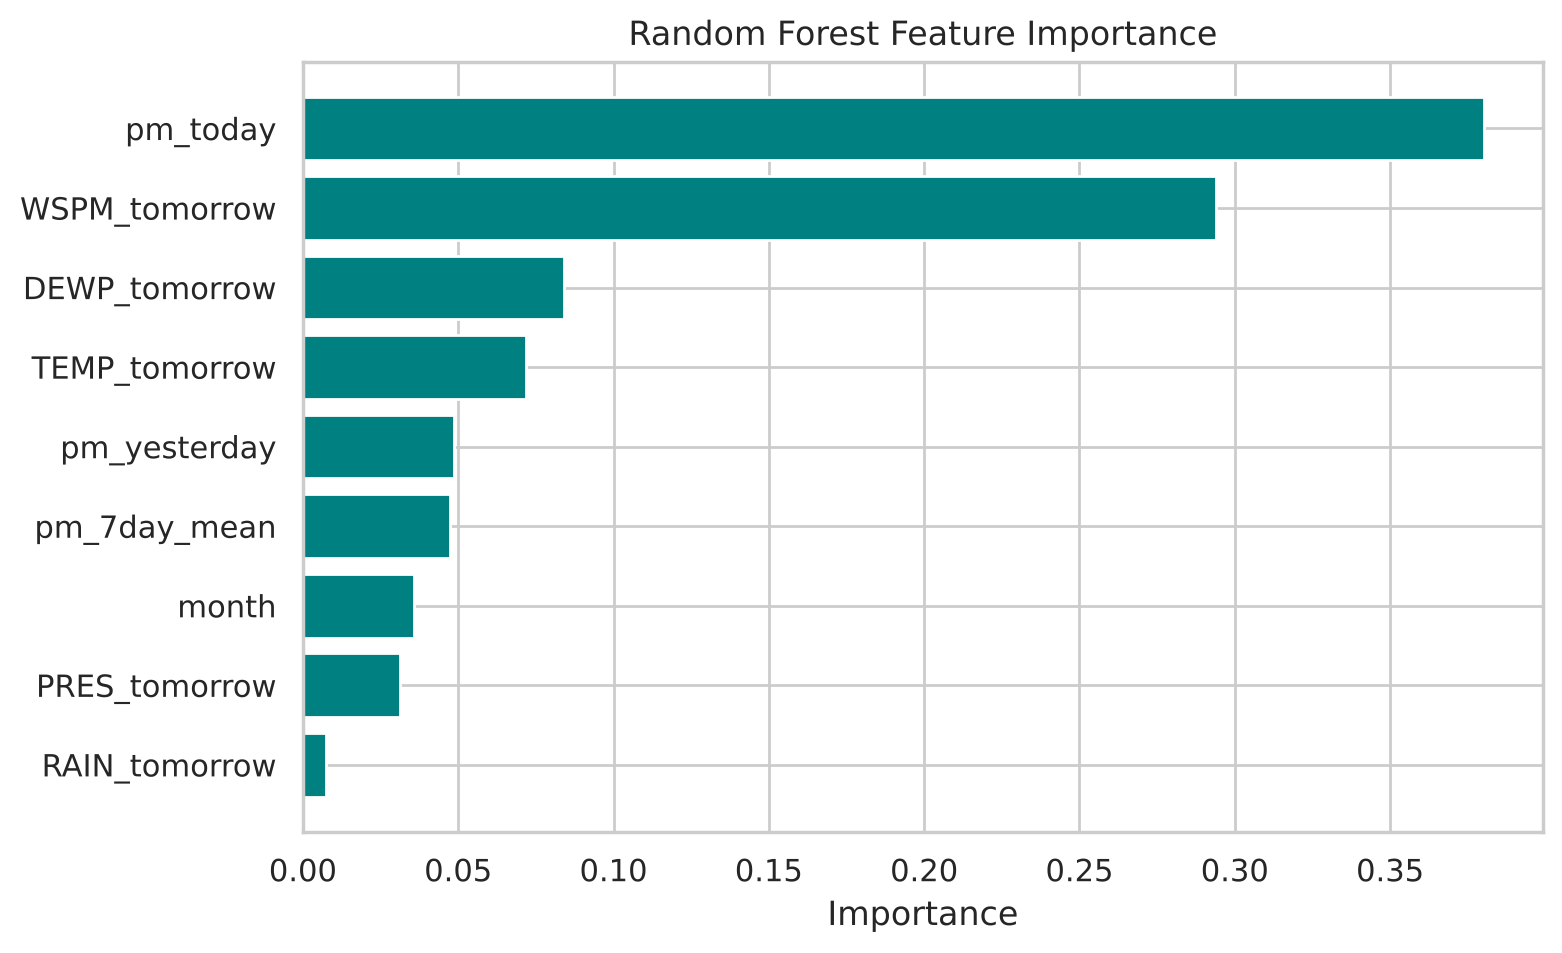

pm_today         0.380
WSPM_tomorrow    0.294
DEWP_tomorrow    0.084
TEMP_tomorrow    0.072
pm_yesterday     0.049
pm_7day_mean     0.047
month            0.036
PRES_tomorrow    0.031
RAIN_tomorrow    0.008
dtype: float64

In [27]:
importance = pd.Series(rf.feature_importances_, index=features).sort_values()
plt.figure(figsize=(8, 5))
plt.barh(importance.index, importance.values, color="teal")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()

importance.sort_values(ascending=False).round(3)

In [28]:
# is the forecast useful as a warning? (China's 24-hour PM2.5 standard = 75 µg/m³)
warn = pd.DataFrame({"actual_above_75": y_test > 75, "forecast_above_75": pred > 75})
print(pd.crosstab(warn["actual_above_75"], warn["forecast_above_75"]), "\n")

hits = (warn["actual_above_75"] & warn["forecast_above_75"]).sum()
print(f"Polluted days correctly warned : {hits} of {warn['actual_above_75'].sum()}"
      f" ({hits / warn['actual_above_75'].sum():.1%})")

level_actual = pd.cut(y_test, bins=bins, labels=levels).cat.codes
level_pred = pd.cut(pred, bins=bins, labels=levels).cat.codes
print(f"AQI level exactly right        : {(level_actual == level_pred).mean():.1%}")
print(f"AQI level within one level     : {((level_actual - level_pred).abs() <= 1).mean():.1%}")

forecast_above_75  False  True 
actual_above_75                
False                146     57
True                  24    137 

Polluted days correctly warned : 137 of 161 (85.1%)
AQI level exactly right        : 40.9%
AQI level within one level     : 90.4%
